In [75]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from arch import arch_model

In [76]:
# Any Yahoo Finance symbol. Everything below uses this value.
ticker = "NVDA"
start = "2022-01-01"
# yfinance treats end as exclusive, so tomorrow includes the day this cell is run.
end = pd.Timestamp.today().normalize() + pd.Timedelta(days=1)

df = yf.download(ticker, start=start, end=end, progress=False)
if df.empty:
    raise ValueError(f"No price data returned for {ticker}")

close = df["Close"]
prices = close.iloc[:, 0] if isinstance(close, pd.DataFrame) else close
prices = prices.dropna()
prices.name = ticker

try:
    currency = yf.Ticker(ticker).fast_info.currency or ""
except Exception:
    currency = ""

diff_prices = prices.diff().dropna()
returns = prices.pct_change().dropna() * 100

log_returns = np.log(prices / prices.shift(1)).dropna() * 100
log_returns.name = ticker

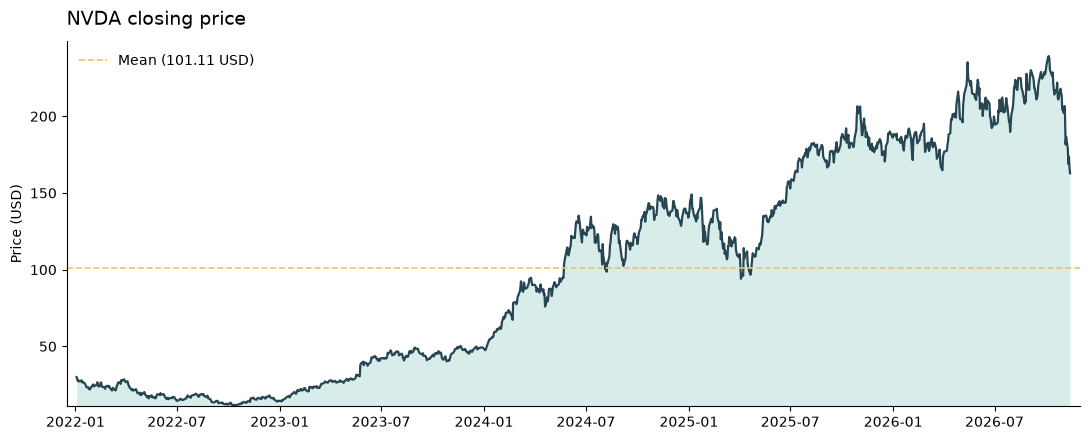

In [77]:
fig, ax = plt.subplots(figsize=(11, 4.5))

floor = float(prices.min()) * 0.97
ax.fill_between(prices.index, prices, floor, color="#2a9d8f", alpha=0.18, linewidth=0)
ax.plot(prices.index, prices, color="#264653", linewidth=1.6)

mean = float(prices.mean())
mean_label = f"Mean ({mean:,.2f} {currency})" if currency else f"Mean ({mean:,.2f})"
ax.axhline(
    mean,
    color="#e9c46a",
    linewidth=1.2,
    linestyle="--",
    label=mean_label,
)

ax.set_title(f"{ticker} closing price", loc="left", fontsize=14, pad=12)
ax.set_ylabel(f"Price ({currency})" if currency else "Price")
ax.set_ylim(floor, float(prices.max()) * 1.04)
ax.legend(frameon=False, loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

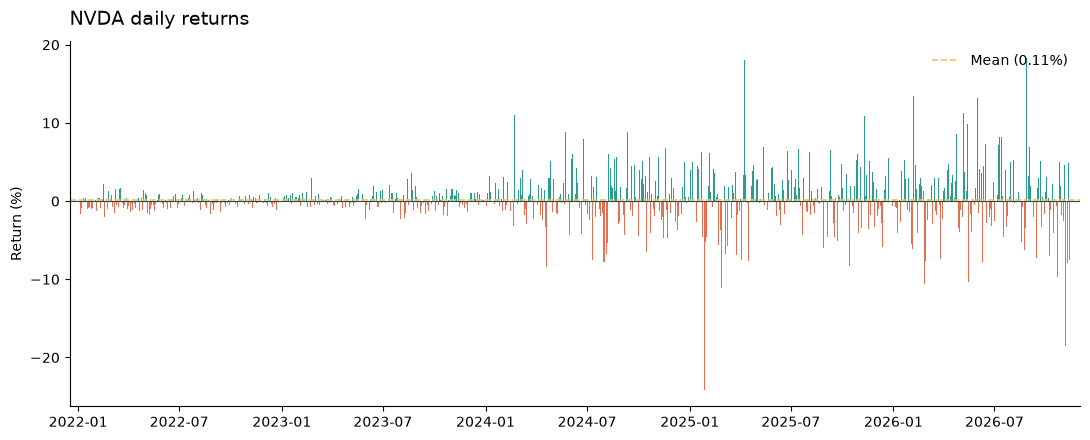

In [78]:
fig, ax = plt.subplots(figsize=(11, 4.5))

colors = np.where(diff_prices.to_numpy() >= 0, "#2a9d8f", "#e76f51")
ax.bar(returns.index, diff_prices, color=colors, width=1.0, linewidth=0)
ax.axhline(0, color="#264653", linewidth=0.8)

mean = float(diff_prices.mean())
ax.axhline(
    mean,
    color="#e9c46a",
    linewidth=1.2,
    linestyle="--",
    label=f"Mean ({mean:.2f}%)",
)

ax.set_title(f"{ticker} daily returns", loc="left", fontsize=14, pad=12)
ax.set_ylabel("Return (%)")
ax.legend(frameon=False, loc="upper right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

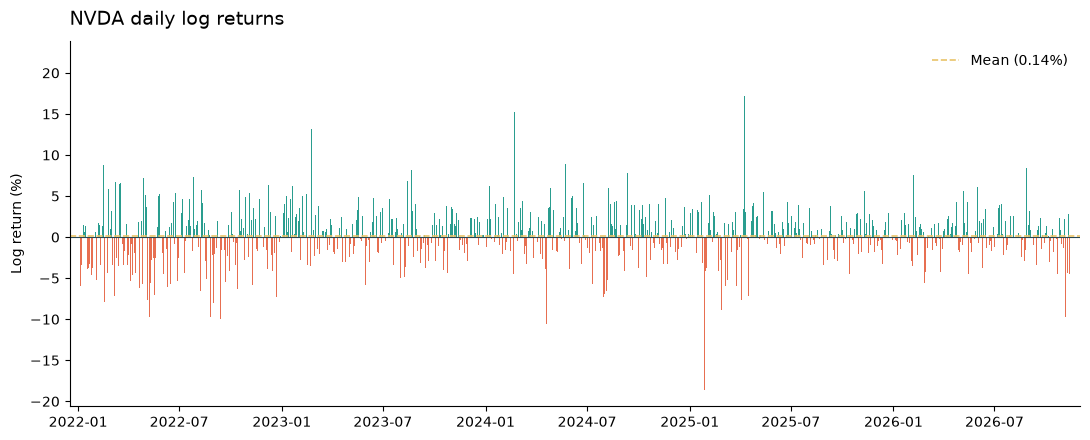

In [79]:
fig, ax = plt.subplots(figsize=(11, 4.5))

colors = np.where(log_returns.to_numpy() >= 0, "#2a9d8f", "#e76f51")
ax.bar(log_returns.index, log_returns, color=colors, width=1.0, linewidth=0)
ax.axhline(0, color="#264653", linewidth=0.8)

mean = float(log_returns.mean())
ax.axhline(
    mean,
    color="#e9c46a",
    linewidth=1.2,
    linestyle="--",
    label=f"Mean ({mean:.2f}%)",
)

ax.set_title(f"{ticker} daily log returns", loc="left", fontsize=14, pad=12)
ax.set_ylabel("Log return (%)")
ax.legend(frameon=False, loc="upper right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

                           AR - GARCH Model Results                           
Dep. Variable:                   NVDA   R-squared:                       0.001
Mean Model:                        AR   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3126.93
Distribution:                  Normal   AIC:                           6263.87
Method:            Maximum Likelihood   BIC:                           6289.40
                                        No. Observations:                 1220
Date:                Sat, Nov 14 2026   Df Residuals:                     1218
Time:                        19:55:16   Df Model:                            2
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
Const          0.2125  8.920e-02      2.382  1.720e-02 

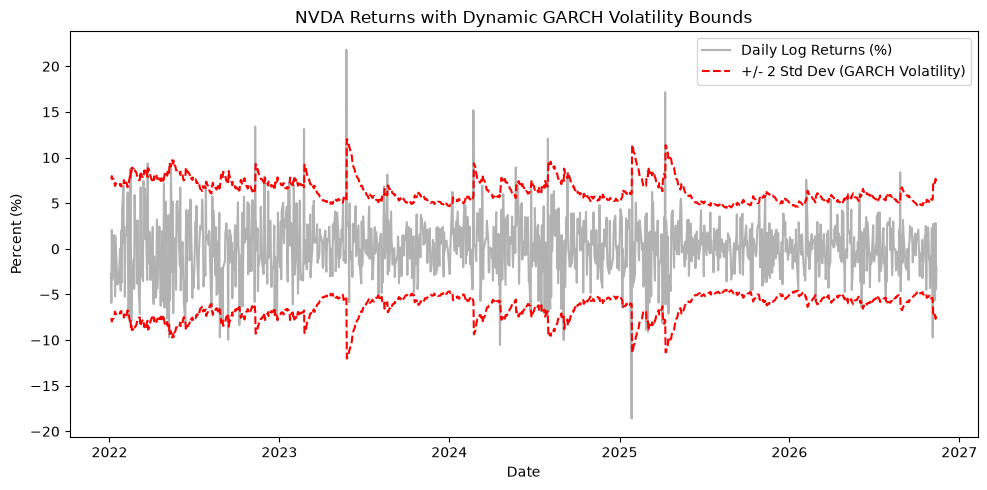


--- NVDA 5-day forecast variance ---
                  h.1        h.2        h.3        h.4        h.5
Date                                                             
2026-11-13  13.701912  13.624652  13.537656  13.453721  13.372753


In [80]:
# 3. Define and fit an ARMA(1,1) + GARCH(1,1) model
# mean='AR', lags=1 specifies an AR(1) mean equation (you can adjust for ARMA)
# vol='Garch', p=1, q=1 specifies a standard GARCH(1,1) volatility equation
model = arch_model(log_returns, mean="AR", lags=1, vol="GARCH", p=1, o=0, q=1, dist="normal")

# Fit the model to the data
results = model.fit(disp="off")

# Print the parameter estimates and summary statistics
print(results.summary())

# 4. Extract the conditional volatility (standard deviation over time)
conditional_volatility = results.conditional_volatility

# 5. Plot the standardized returns alongside the estimated time-varying volatility envelope
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    log_returns.index,
    log_returns,
    color="gray",
    alpha=0.6,
    label="Daily Log Returns (%)",
)
ax.plot(
    conditional_volatility.index,
    2 * conditional_volatility,
    color="red",
    linestyle="--",
    label="+/- 2 Std Dev (GARCH Volatility)",
)
ax.plot(
    conditional_volatility.index,
    -2 * conditional_volatility,
    color="red",
    linestyle="--",
)

ax.set_title(f"{ticker} Returns with Dynamic GARCH Volatility Bounds")
ax.set_xlabel("Date")
ax.set_ylabel("Percent (%)")
ax.legend()
plt.tight_layout()
plt.show()

# 6. Generate multi-step volatility and return forecasts for the next 5 days
forecasts = results.forecast(horizon=5)
print(f"\n--- {ticker} 5-day forecast variance ---")
print(forecasts.variance.dropna().tail(1))